# Monitoring and reports 

Covers the data monitor, model monitor, pipeline monitor, infrastructure monitor, dashboard and reports, with a single cleanup check at the end. The dashboard's report-index link is populated once the Reports section has run; re-run the Dashboard section afterwards if you want it refreshed.

In [1]:
from importlib.metadata import version, PackageNotFoundError
try:
    _sm_ver = version("sagemaker")
except PackageNotFoundError:
    _sm_ver = "0"
if int(_sm_ver.split(".")[0]) != 2:
    %pip uninstall -q -y sagemaker sagemaker-core sagemaker-train sagemaker-serve sagemaker-mlops
    %pip install -q "sagemaker>=2.200,<3"
    print(f"Replaced sagemaker {_sm_ver} with v2 - restarting kernel; re-run the notebook from the top.")
    import IPython
    IPython.Application.instance().kernel.do_shutdown(restart=True)
else:
    print("sagemaker", _sm_ver)

sagemaker 2.257.7


## Bootstrap

Path, config, boto3 session/clients, shared S3/CloudWatch helpers and the one-off Model Monitor analyzer helper.

In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import io, json, time
import boto3, numpy as np, pandas as pd
from botocore.exceptions import ClientError
from src.pamap2.config import load_config, s3_uri
from src.pamap2.schema import ACTIVITY_NAMES
from src.pamap2 import evaluation as E
from src.pamap2 import monitoring as M
cfg = load_config()
session = boto3.Session(region_name=cfg["region"])
print("Caller:", session.client("sts").get_caller_identity()["Arn"])
s3 = session.client("s3")
cw = session.client("cloudwatch")
sm = session.client("sagemaker")
SPLITS = s3_uri(cfg, "splits")
REPORTS = s3_uri(cfg, "models", "reports/")
MON = lambda key: s3_uri(cfg, "monitoring", key)
NS = cfg["monitoring_namespace"]

def split_key(uri):
    b, k = uri[len("s3://"):].split("/", 1)
    return b, k
def read_bytes(uri):
    b, k = split_key(uri)
    return s3.get_object(Bucket=b, Key=k)["Body"].read()
def read_bytes_or_none(uri):
    try:
        return read_bytes(uri)
    except ClientError as e:
        if e.response["Error"]["Code"] in ("NoSuchKey", "404"):
            return None
        raise
def read_parquet(name):
    return pd.read_parquet(io.BytesIO(read_bytes(SPLITS + name)))
def read_json(uri):
    return json.loads(read_bytes(uri))
def write_json(uri, obj):
    b, k = split_key(uri)
    s3.put_object(Bucket=b, Key=k, Body=json.dumps(obj, indent=2).encode())
    print("Wrote", uri)
def put_text(uri, text):
    b, k = split_key(uri)
    s3.put_object(Bucket=b, Key=k, Body=text.encode())
    return uri
def exists(uri):
    b, k = split_key(uri)
    try:
        s3.head_object(Bucket=b, Key=k)
        return True
    except ClientError:
        return False
def latest_subprefix(uri_prefix):
    """Newest child 'folder' (timestamped run folders sort lexicographically)."""
    b, k = split_key(uri_prefix)
    r = s3.list_objects_v2(Bucket=b, Prefix=k, Delimiter="/")
    subs = sorted(p["Prefix"] for p in r.get("CommonPrefixes", []))
    return f"s3://{b}/{subs[-1]}" if subs else None
def publish(metrics):
    """metrics: {name: value} -> custom namespace (put_metric_data)."""
    cw.put_metric_data(Namespace=NS, MetricData=[{"MetricName": n, "Value": float(v), "Unit": "None"} for n, v in metrics.items()])
    print("Published", metrics)

def safe_publish(metrics):
    try:
        publish(metrics)
    except Exception as e:   # never mask the original error
        print("WARNING: publish failed:", e)
def report_failure(job_name):
    try:
        print("FailureReason:", sm.describe_processing_job(ProcessingJobName=job_name).get("FailureReason"))
    except Exception as e:
        print("Could not describe job:", e)

FEATURES = read_json(SPLITS + "feature_columns.json")
LABEL_MAP = E.load_label_map(read_json(SPLITS + "label_map.json"))   # class index -> activity_id
K = len(LABEL_MAP)
ACTIVITY_IDS = list(LABEL_MAP.values())
print(K, "classes;", len(FEATURES), "features")

Caller: arn:aws:sts::887757489409:assumed-role/LabRole/SageMaker
18 classes; 128 features


In [3]:
import sagemaker
from sagemaker.processing import Processor, ProcessingInput, ProcessingOutput
sm_session = sagemaker.Session(boto_session=session)
ANALYZER = sagemaker.image_uris.retrieve("model-monitor", cfg["region"])

def run_analyzer(name, env, inputs, output_uri):
    """One-off Model Monitor analyzer job (ml.m5.large x1). inputs: [(s3_uri, container_dest, input_name)]."""
    proc = Processor(role=cfg["role_arn"], image_uri=ANALYZER, instance_count=1, instance_type="ml.m5.large",
                     volume_size_in_gb=20, max_runtime_in_seconds=3600, env=env, sagemaker_session=sm_session)
    proc.run(inputs=[ProcessingInput(source=s, destination=d, input_name=n) for s, d, n in inputs],
             outputs=[ProcessingOutput(source="/opt/ml/processing/output", destination=output_uri, output_name="result")],
             job_name=name, wait=True, logs=False)
    return output_uri
from sagemaker.model_monitor import DefaultModelMonitor
from sagemaker.model_monitor import ModelQualityMonitor
from sagemaker.model_monitor.dataset_format import DatasetFormat

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


/opt/conda/lib/python3.12/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


## Data monitor 

Data-quality baseline (statistics + constraints) from the **train** features with `DefaultModelMonitor.suggest_baseline`, then a one-off Model Monitor analyzer job on the **production** features. Batch only: no endpoint, no monitoring schedule.

 Outputs: `monitoring/data-quality/baseline/` and `monitoring/data-quality/runs/<ts>/`.

### Monitor datasets 

In [4]:
train_uri = put_text(MON("data-quality/input/train.csv"), M.to_monitor_csv(read_parquet("train.parquet"), FEATURES))
prod_df = read_parquet("production.parquet")
prod_uri = put_text(MON("data-quality/input/production.csv"), M.to_monitor_csv(prod_df, FEATURES))
print(train_uri, prod_uri, len(prod_df), "production rows")


s3://pamap2-har-887757489409-us-east-1/monitoring/data-quality/input/train.csv s3://pamap2-har-887757489409-us-east-1/monitoring/data-quality/input/production.csv 4156 production rows


### Baseline on train 

In [5]:
DQ_BASELINE = MON("data-quality/baseline/")
dq_monitor = DefaultModelMonitor(role=cfg["role_arn"], instance_count=1, instance_type="ml.m5.large",
                              volume_size_in_gb=20, max_runtime_in_seconds=3600, sagemaker_session=sm_session)
dq_monitor.suggest_baseline(baseline_dataset=train_uri, dataset_format=DatasetFormat.csv(header=True),
                         output_s3_uri=DQ_BASELINE, wait=True, logs=False)
stats = read_json(DQ_BASELINE + "statistics.json")
cons = read_json(DQ_BASELINE + "constraints.json")
print(len(stats["features"]), "features profiled;", len(cons["features"]), "constraints")
cons_by_name = {c["name"]: c for c in cons["features"]}
display(pd.DataFrame([{"feature": f["name"], "type": f["inferred_type"],
                       "completeness_threshold": cons_by_name.get(f["name"], {}).get("completeness")}
                      for f in stats["features"][:10]]))


/opt/conda/lib/python3.12/site-packages/sagemaker/model_monitor/model_monitoring.py:176: SageMakerV2DeprecationWarning: DefaultModelMonitor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.shapes.MonitoringSchedule`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
DefaultModelMonitor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.shapes.MonitoringSchedule`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
/opt/conda/lib/python3.12/site-packages/sagemaker/processing.py:138: SageMakerV2DeprecationWarning: Processor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `DataProcessor` (`from sagemaker.mlops.processing

.......................................................................................................................!128 features profiled; 128 constraints


,feature,type,completeness_threshold
0,hand_acc16_x_mean,Fractional,1.0
1,hand_acc16_x_std,Fractional,1.0
2,hand_acc16_x_min,Fractional,1.0
3,hand_acc16_x_max,Fractional,1.0
4,hand_acc16_x_energy,Fractional,1.0
5,hand_acc16_x_domfreq,Fractional,1.0
6,hand_acc16_y_mean,Fractional,1.0
7,hand_acc16_y_std,Fractional,1.0
8,hand_acc16_y_min,Fractional,1.0
9,hand_acc16_y_max,Fractional,1.0


### Monitoring job on production features 

In [6]:
dq_stamp = time.strftime("%Y%m%d-%H%M%S")
DQ_RUN = MON(f"data-quality/runs/{dq_stamp}/")
env = {"dataset_format": json.dumps(DatasetFormat.csv(header=True)), "dataset_source": "/opt/ml/processing/input/data",
       "output_path": "/opt/ml/processing/output", "publish_cloudwatch_metrics": "Disabled",
       "baseline_constraints": "/opt/ml/processing/baseline/constraints/constraints.json",
       "baseline_statistics": "/opt/ml/processing/baseline/stats/statistics.json"}
dq_job_name = f"{cfg['prefix']}-data-monitor-{dq_stamp}"
try:
    run_analyzer(dq_job_name, env, [
        (prod_uri, "/opt/ml/processing/input/data", "data"),
        (DQ_BASELINE + "constraints.json", "/opt/ml/processing/baseline/constraints", "constraints"),
        (DQ_BASELINE + "statistics.json", "/opt/ml/processing/baseline/stats", "statistics")], DQ_RUN)
except Exception:
    report_failure(dq_job_name)
    safe_publish({"DataJobFailed": 1})
    raise
safe_publish({"DataJobFailed": 0})


INFO:sagemaker:Creating processing-job with name pamap2-har-data-monitor-20261011-181715


.......................................................................................................................!Published {'DataJobFailed': 0}


### Statistics, constraints and violations

In [7]:
assert exists(DQ_RUN + "statistics.json"), "no statistics.json in run output - job incomplete; absent violations would not mean zero"
print("Run statistics:", DQ_RUN + "statistics.json")
print("Run constraints:", DQ_RUN + "constraints.json", "| exists:", exists(DQ_RUN + "constraints.json"))
v = M.parse_violations(read_bytes_or_none(DQ_RUN + "constraint_violations.json"))   # missing file = 0 violations
print("Violations:", v["count"], "->", v["status"])
display(pd.DataFrame(v["violations"], columns=["feature", "check_type", "description"]))
write_json(DQ_RUN + "violations_summary.json", v)
publish({"DataViolationCount": v["count"]})


Run statistics: s3://pamap2-har-887757489409-us-east-1/monitoring/data-quality/runs/20261011-181715/statistics.json
Run constraints: s3://pamap2-har-887757489409-us-east-1/monitoring/data-quality/runs/20261011-181715/constraints.json | exists: True
Violations: 0 -> ok


,feature,check_type,description


Wrote s3://pamap2-har-887757489409-us-east-1/monitoring/data-quality/runs/20261011-181715/violations_summary.json
Published {'DataViolationCount': 0}


## Model monitor

`ModelQualityMonitor` (multiclass) baselined on the pipeline's **test** predictions (`test_predictions.csv` from the evaluate step) vs labels, then a one-off analyzer job on the pipeline's **production** predictions file vs `true_activity_id`, compared with `xgboost_eval.json`. Batch only: no endpoint or schedule.

### Baseline dataset: test predictions (from the pipeline evaluate step) vs test labels

In [8]:
test = read_parquet("test.parquet").reset_index(drop=True)
eval_report = read_json(REPORTS + "xgboost_eval.json")
tp = pd.read_csv(io.BytesIO(read_bytes(eval_report["test_predictions_uri"])))   # label, predicted_class, confidence

assert len(tp) == len(test), (len(tp), len(test))
assert (tp["label"].to_numpy() == test["label"].to_numpy()).all(), "test_predictions.csv labels differ from the test split"

test_preds = pd.DataFrame({"predicted_activity_id": [LABEL_MAP[int(c)] for c in tp["predicted_class"]],
                           "confidence": tp["confidence"], "true_activity_id": test["activity_id"]})
base_df, dropped = M.to_model_quality_frame(test_preds)
print("Baseline rows:", len(base_df), "| dropped NaN labels:", dropped)
base_uri = put_text(MON("model-quality/input/baseline.csv"), base_df.to_csv(index=False))
base_metrics = E.classification_metrics(base_df["label"], base_df["prediction"], ACTIVITY_IDS)
print(f"Local test macro-F1={base_metrics['macro_f1']:.4f} | xgboost_eval.json macro-F1={eval_report['macro_f1']:.4f}")

if abs(base_metrics["macro_f1"] - eval_report["macro_f1"]) > 1e-3:
    print("WARNING: baseline macro-F1 differs from xgboost_eval.json by > 1e-3 - test predictions may be stale")

Baseline rows: 956 | dropped NaN labels: 0
Local test macro-F1=0.8715 | xgboost_eval.json macro-F1=0.8715


### Baseline job

In [9]:
MQ_BASELINE = MON("model-quality/baseline/")

mq = ModelQualityMonitor(role=cfg["role_arn"], instance_count=1, instance_type="ml.m5.large", volume_size_in_gb=20,
                         max_runtime_in_seconds=3600, sagemaker_session=sm_session)
mq.suggest_baseline(baseline_dataset=base_uri, dataset_format=DatasetFormat.csv(header=True), output_s3_uri=MQ_BASELINE,
                    problem_type="MulticlassClassification", inference_attribute="prediction",
                    probability_attribute="probability", ground_truth_attribute="label", wait=True, logs=False)
for f in ("statistics.json", "constraints.json"):
    print(MQ_BASELINE + f, "exists:", exists(MQ_BASELINE + f))


INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
/opt/conda/lib/python3.12/site-packages/sagemaker/model_monitor/model_monitoring.py:176: SageMakerV2DeprecationWarning: ModelQualityMonitor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.shapes.MonitoringSchedule`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating processing-job with name baseline-suggestion-job-2026-10-11-18-27-20-849


.......................................................................................................................!s3://pamap2-har-887757489409-us-east-1/monitoring/model-quality/baseline/statistics.json exists: True
s3://pamap2-har-887757489409-us-east-1/monitoring/model-quality/baseline/constraints.json exists: True


### Production predictions vs true_activity_id

In [10]:
eval_report = read_json(REPORTS + "xgboost_eval.json")

preds = pd.read_parquet(io.BytesIO(read_bytes(eval_report["predictions_uri"])))
print("Using", eval_report["predictions_uri"])
n_prod = len(read_parquet("production.parquet"))   # split file is already restricted to train classes (= pipeline batch input)

assert len(preds) == n_prod, f"predictions rows {len(preds)} != production split rows {n_prod}"

prod_df, dropped = M.to_model_quality_frame(preds)
if prod_df.empty:
    raise RuntimeError("no labelled production rows (true_activity_id all NaN)")

print("Production rows:", len(prod_df), "| dropped rows with NaN label/prediction/probability:", dropped)
prod_uri = put_text(MON("model-quality/input/production.csv"), prod_df.to_csv(index=False))
prod_metrics = E.classification_metrics(prod_df["label"], prod_df["prediction"], ACTIVITY_IDS)

Using s3://pamap2-har-887757489409-us-east-1/models/pipeline/predictions/jlqa6fgd20cq/predictions.parquet
Production rows: 4156 | dropped rows with NaN label/prediction/probability: 0


### One-off monitoring job

In [11]:
mq_stamp = time.strftime("%Y%m%d-%H%M%S")
MQ_RUN = MON(f"model-quality/runs/{mq_stamp}/")
env = {"analysis_type": "MODEL_QUALITY", "problem_type": "MulticlassClassification",
       "dataset_format": json.dumps(DatasetFormat.csv(header=True)), "dataset_source": "/opt/ml/processing/input/data",
       "inference_attribute": "prediction", "probability_attribute": "probability", "ground_truth_attribute": "label",
       "output_path": "/opt/ml/processing/output", "publish_cloudwatch_metrics": "Disabled",
       "baseline_constraints": "/opt/ml/processing/baseline/constraints/constraints.json",
       "baseline_statistics": "/opt/ml/processing/baseline/stats/statistics.json"}
mq_job_name = f"{cfg['prefix']}-model-monitor-{mq_stamp}"
try:
    run_analyzer(mq_job_name, env, [
        (prod_uri, "/opt/ml/processing/input/data", "data"),
        (MQ_BASELINE + "constraints.json", "/opt/ml/processing/baseline/constraints", "constraints"),
        (MQ_BASELINE + "statistics.json", "/opt/ml/processing/baseline/stats", "statistics")], MQ_RUN)
except Exception:
    report_failure(mq_job_name)
    safe_publish({"ModelJobFailed": 1})
    raise
safe_publish({"ModelJobFailed": 0})


INFO:sagemaker:Creating processing-job with name pamap2-har-model-monitor-20261011-183726


.........................................................................................!Published {'ModelJobFailed': 0}


### Violations and quality drift vs xgboost_eval.json

In [12]:
assert exists(MQ_RUN + "statistics.json"), "no statistics.json in run output - job incomplete; absent violations would not mean zero"
v = M.parse_violations(read_bytes_or_none(MQ_RUN + "constraint_violations.json"))
print("Violations:", v["count"], "->", v["status"])
display(pd.DataFrame(v["violations"], columns=["feature", "check_type", "description"]))
drift = M.quality_drift(eval_report["macro_f1"], prod_metrics["macro_f1"], cfg["monitoring_drift_threshold"])
print(drift)
display(pd.DataFrame([{"metric": m, "baseline_eval": eval_report[m], "production": prod_metrics[m]} for m in ("macro_f1", "accuracy")]))
print("NOTE: seen-subject production windows make these numbers optimistic (chronological split).")
write_json(MQ_RUN + "violations_summary.json", {**v, "drift": drift})
publish({"ModelMacroF1": prod_metrics["macro_f1"], "ModelAccuracy": prod_metrics["accuracy"],
         "ModelViolationCount": v["count"], "ModelDegraded": int(drift["degraded"])})


Violations: 5 -> violations


,feature,check_type,description
0,None,LessThanThreshold,Metric weightedF2 with 0.8411569946079043 +/- ...
1,None,LessThanThreshold,Metric accuracy with 0.8435996150144369 +/- 0....
2,None,LessThanThreshold,Metric weightedRecall with 0.8435996150144369 ...
3,None,LessThanThreshold,Metric weightedPrecision with 0.84604226815120...
4,None,LessThanThreshold,Metric weightedF1 with 0.8402401909625938 +/- ...


{'baseline_macro_f1': 0.8714660469922806, 'production_macro_f1': 0.8355225450598911, 'drop': 0.03594350193238949, 'threshold': 0.05, 'degraded': False}


,metric,baseline_eval,production
0,macro_f1,0.871466,0.835523
1,accuracy,0.880753,0.843600


NOTE: seen-subject production windows make these numbers optimistic (chronological split).
Wrote s3://pamap2-har-887757489409-us-east-1/monitoring/model-quality/runs/20261011-183726/violations_summary.json
Published {'ModelMacroF1': 0.8355225450598911, 'ModelAccuracy': 0.8435996150144369, 'ModelViolationCount': 5, 'ModelDegraded': 0}


## Pipeline monitor 

Monitors the SageMaker Pipeline run by notebook 3: execution status, the steps of the latest execution (with failure reasons), duration and status counts. 

The result is stored as `monitoring/pipeline/runs/<ts>/summary.json` and two custom metrics are published to `pamap2-har/Monitoring`: `PipelineExecutionFailed` (1 when the latest execution failed) and `PipelineFailedSteps`.

### Executions and steps of the latest execution

In [13]:
PIPE = cfg["pipeline_name"]

try:
    executions = [e for p in sm.get_paginator("list_pipeline_executions").paginate(PipelineName=PIPE)
                  for e in p["PipelineExecutionSummaries"]]
except ClientError as e:
    if e.response["Error"]["Code"] not in ("ResourceNotFound", "ValidationException"):
        raise
    executions = []
pipe_steps = []

if executions:
    latest_exec = max(executions, key=lambda e: e["StartTime"])
    pipe_steps = [s for p in sm.get_paginator("list_pipeline_execution_steps").paginate(
                      PipelineExecutionArn=latest_exec["PipelineExecutionArn"]) for s in p["PipelineExecutionSteps"]]
    display(pd.DataFrame([{"execution": e["PipelineExecutionArn"].rsplit("/", 1)[-1], "status": e["PipelineExecutionStatus"],
                           "started": e["StartTime"], "modified": e.get("LastModifiedTime")}
                          for e in sorted(executions, key=lambda e: e["StartTime"], reverse=True)]))
    display(pd.DataFrame([{"step": s["StepName"], "status": s["StepStatus"], "reason": s.get("FailureReason", "")[:120]}
                          for s in reversed(pipe_steps)]))
else:
    print("No pipeline executions for", PIPE, "- nothing to monitor (run 3_train_evaluate_deploy.ipynb first).")

,execution,status,started,modified
0,raldjfb0jcce,Failed,2026-10-11 17:44:32.550000+00:00,None
1,jlqa6fgd20cq,Succeeded,2026-10-11 17:12:01.163000+00:00,None
2,h8xqivro7ysc,Succeeded,2026-10-11 16:20:59.759000+00:00,None


,step,status,reason
0,PreprocessSplits,Succeeded,
1,TrainModel,Succeeded,
2,EvaluateModel,Succeeded,
3,CheckMacroF1,Succeeded,
4,MacroF1BelowThreshold,Failed,Test macro-F1 is below MacroF1Threshold 0.999


### Status summary and metrics

In [14]:
pipe_status = M.pipeline_status(executions, pipe_steps)
if pipe_status["executions"]:
    print({k: v for k, v in pipe_status.items() if k != "failed_steps"})
    for f in pipe_status["failed_steps"]:
        print("FAILED STEP:", f["step"], "-", f["reason"])
    pipe_stamp = time.strftime("%Y%m%d-%H%M%S")
    write_json(MON(f"pipeline/runs/{pipe_stamp}/summary.json"), pipe_status)
    publish(pipe_status["metrics"])
else:
    print("Nothing published: no pipeline executions yet.")

{'executions': 3, 'latest_arn': 'arn:aws:sagemaker:us-east-1:887757489409:pipeline/pamap2-har-pipeline/execution/raldjfb0jcce', 'latest_status': 'Failed', 'failed': 1, 'duration_s': None, 'status_counts': {'Failed': 1, 'Succeeded': 2}, 'metrics': {'PipelineExecutionFailed': 1, 'PipelineFailedSteps': 1}}
FAILED STEP: MacroF1BelowThreshold - Test macro-F1 is below MacroF1Threshold 0.999
Wrote s3://pamap2-har-887757489409-us-east-1/monitoring/pipeline/runs/20261011-184500/summary.json
Published {'PipelineExecutionFailed': 1, 'PipelineFailedSteps': 1}


## Infrastructure monitor 

CloudWatch alarms on SageMaker job utilisation  plus alarms on the custom `pamap2-har/Monitoring` metrics published by the data, model and pipeline monitors (violation counts, degradation, job-failed 0/1, pipeline execution failed, pipeline failed steps) and a native pipeline alarm on `ExecutionFailed` (`AWS/Sagemaker/ModelBuildingPipeline`).Alarm state is shown here and on the dashboard. 

Alarm creation is idempotent (`put_metric_alarm` overwrites). Job alarms are Metrics Insights query alarms over the whole job namespace (one query per job namespace and metric), so future jobs are watched too.

Custom-metric alarms use `TreatMissingData=ignore` so the last evaluated state persists between manual runs.

In [15]:
def put_alarm(spec):
    """put_metric_alarm; if AccessDenied on actions, retry without AlarmActions (none are configured by default)."""
    try:
        cw.put_metric_alarm(**spec)
    except ClientError as e:
        if e.response["Error"]["Code"] != "AccessDenied" or "AlarmActions" not in spec:
            raise
        print("WARNING: AccessDenied for alarm actions; creating", spec["AlarmName"], "without actions")
        cw.put_metric_alarm(**{k: v for k, v in spec.items() if k != "AlarmActions"})


### Job-utilisation alarms

In [16]:
prefix = cfg["monitoring_alarm_prefix"]
created = []
THRESHOLDS = {"CPUUtilization": 95, "MemoryUtilization": 90, "DiskUtilization": 85}
for job_type in M.JOB_NAMESPACES:
    for metric, thr in THRESHOLDS.items():
        spec = M.alarm_spec(job_type, metric, thr, prefix=prefix)   # Metrics Insights query: covers every current and future job
        put_alarm(spec); created.append(spec["AlarmName"])
print("Created/updated:", created)


Created/updated: ['pamap2-har-training-cpuutilization', 'pamap2-har-training-memoryutilization', 'pamap2-har-training-diskutilization', 'pamap2-har-transform-cpuutilization', 'pamap2-har-transform-memoryutilization', 'pamap2-har-transform-diskutilization', 'pamap2-har-processing-cpuutilization', 'pamap2-har-processing-memoryutilization', 'pamap2-har-processing-diskutilization']


### Monitoring-metric alarms

In [17]:
for metric, thr in {"DataJobFailed": 0, "ModelJobFailed": 0, "DataViolationCount": 0,
                    "ModelViolationCount": 0, "ModelDegraded": 0, "PipelineExecutionFailed": 0,
                    "PipelineFailedSteps": 0}.items():
    spec = M.alarm_spec("custom", metric, thr, prefix=prefix, namespace=NS, period=3600)
    put_alarm(spec); print("Created/updated", spec["AlarmName"])

Created/updated pamap2-har-DataJobFailed
Created/updated pamap2-har-ModelJobFailed
Created/updated pamap2-har-DataViolationCount
Created/updated pamap2-har-ModelViolationCount
Created/updated pamap2-har-ModelDegraded
Created/updated pamap2-har-PipelineExecutionFailed
Created/updated pamap2-har-PipelineFailedSteps


### Native pipeline alarm (`ExecutionFailed`)

In [18]:
spec = M.pipeline_alarm_spec(cfg["pipeline_name"], prefix=prefix)
put_alarm(spec); print("Created/updated", spec["AlarmName"])

Created/updated pamap2-har-pipeline-executionfailed


### Alarm states

In [19]:
alarms = cw.describe_alarms(AlarmNamePrefix=prefix + "-")["MetricAlarms"]
def _alarm_metric(a):
    # Metric-math alarms have no top-level MetricName; show their expression / metric names instead.
    if "MetricName" in a:
        return a["MetricName"]
    return ", ".join(m.get("Expression") or m.get("MetricStat", {}).get("Metric", {}).get("MetricName", m["Id"])
                     for m in a.get("Metrics", []))
display(pd.DataFrame([{"alarm": a["AlarmName"], "state": a["StateValue"], "metric": _alarm_metric(a)}
                      for a in alarms]))


,alarm,state,metric
0,pamap2-har-DataJobFailed,INSUFFICIENT_DATA,DataJobFailed
1,pamap2-har-DataViolationCount,INSUFFICIENT_DATA,DataViolationCount
2,pamap2-har-ModelDegraded,INSUFFICIENT_DATA,ModelDegraded
3,pamap2-har-ModelJobFailed,INSUFFICIENT_DATA,ModelJobFailed
4,pamap2-har-ModelViolationCount,INSUFFICIENT_DATA,ModelViolationCount
5,pamap2-har-PipelineExecutionFailed,INSUFFICIENT_DATA,PipelineExecutionFailed
6,pamap2-har-PipelineFailedSteps,INSUFFICIENT_DATA,PipelineFailedSteps
7,pamap2-har-pipeline-executionfailed,INSUFFICIENT_DATA,ExecutionFailed
8,pamap2-har-processing-cpuutilization,INSUFFICIENT_DATA,"SELECT MAX(CPUUtilization) FROM ""/aws/sagemake..."
9,pamap2-har-processing-diskutilization,INSUFFICIENT_DATA,"SELECT MAX(DiskUtilization) FROM ""/aws/sagemak..."


## Dashboard 

Creates/overwrites the `pamap2-har-ml` CloudWatch dashboard: job utilisation widgets, custom monitoring metrics (including the pipeline metrics), a pipeline executions widget (started / succeeded / failed), alarm status and a text widget linking the reports and the pipeline. Run after the Pipeline and Infrastructure monitors and ideally the Reports section.

In [20]:
job_metrics = [{"title": f"{jt} {m}", "namespace": ns, "metric": m}
               for jt, ns in M.JOB_NAMESPACES.items() for m in ("CPUUtilization", "MemoryUtilization")]
alarm_arns = [a["AlarmArn"] for a in cw.describe_alarms(AlarmNamePrefix=cfg["monitoring_alarm_prefix"] + "-")["MetricAlarms"]]
links = {"report index (populated after Reports)": MON("reports/index.json"),
         "SageMaker pipeline": f"{cfg['pipeline_name']} (SageMaker Studio > Pipelines)",
         "pipeline monitor summaries": MON("pipeline/runs/")}
body = M.dashboard_body(cfg["region"], job_metrics,
                        ["DataViolationCount", "ModelViolationCount", "ModelMacroF1", "ModelAccuracy", "ModelDegraded",
                         "DataJobFailed", "ModelJobFailed", "PipelineExecutionFailed", "PipelineFailedSteps"],
                        alarm_arns, NS, links, pipeline_name=cfg["pipeline_name"])
resp = cw.put_dashboard(DashboardName=cfg["monitoring_dashboard"], DashboardBody=body)
print("Validation messages:", resp.get("DashboardValidationMessages"))
print(f"https://{cfg['region']}.console.aws.amazon.com/cloudwatch/home?region={cfg['region']}#dashboards:name={cfg['monitoring_dashboard']}")

Validation messages: []
https://us-east-1.console.aws.amazon.com/cloudwatch/home?region=us-east-1#dashboards:name=pamap2-har-ml


## Reports

**SHAP explainability** for the evaluated XGBoost model, then a consolidated index `monitoring/reports/index.json` of the data-quality and model-quality constraints/violations, the pipeline's evaluation, predictions and status summary and the SHAP outputs.

**Why not Clarify:** SageMaker Clarify processing is in maintenance mode and rejects `CreateProcessingJob` for new accounts. SHAP is computed here instead with XGBoost's built-in exact TreeSHAP (`pred_contribs=True`) on the registered model artifact - no job, endpoint or model is created, so this notebook is not billable. SHAP on test windows from seen subjects is still optimistic.

In [21]:
# Local exact TreeSHAP needs the xgboost library matching the training container (cfg["xgboost_version"], e.g. 1.7-1).
XGB_PIN = "xgboost==" + cfg["xgboost_version"].split("-")[0] + ".*"
try:
    import xgboost as xgb
except ImportError:
    %pip install -q "{XGB_PIN}"
    import xgboost as xgb
print("xgboost", xgb.__version__)
PKG_ARN = read_json(REPORTS + "xgboost_eval.json")["model_package_arn"]   # the evaluated package
SHAP_OUT = MON("reports/shap/")

xgboost 2.1.4


### SHAP explainability 

Model: s3://pamap2-har-887757489409-us-east-1/models/pipeline/xgboost/pipelines-jlqa6fgd20cq-TrainModel-cdHcpw9QWP/output/model.tar.gz
Wrote s3://pamap2-har-887757489409-us-east-1/monitoring/reports/shap/20261011-184506/analysis.json
SHAP output: s3://pamap2-har-887757489409-us-east-1/monitoring/reports/shap/20261011-184506/


,lying,sitting,standing,walking,running,cycling,Nordic walking,watching TV,computer work,car driving,ascending stairs,descending stairs,vacuum cleaning,ironing,folding laundry,house cleaning,playing soccer,rope jumping,overall
ankle_acc16_x_mean,0.4812,0.1496,0.0147,1.3164,0.0047,0.0088,0.3569,0.0627,0.1706,0.0921,0.0652,0.0064,0.0076,0.0247,0.0062,0.0650,0.0006,0.0362,0.1594
ankle_acc16_x_min,0.0322,0.0168,0.2005,0.0923,0.2203,0.0021,0.0305,0.0149,0.0558,0.0301,0.1923,0.8039,0.0109,0.0087,0.4263,0.0062,0.0008,0.0000,0.1191
hr_mean,0.0054,0.1397,0.0766,0.0308,0.1001,0.0798,0.0568,0.0007,0.1664,0.1621,0.0291,0.0389,0.0098,0.0691,0.0493,0.0687,0.2222,0.4840,0.0994
ankle_acc16_y_energy,0.0107,0.0531,0.0494,0.0344,0.0190,0.0130,0.0022,0.0016,0.0214,0.0000,0.0123,0.0357,0.0243,0.9662,0.1566,0.3651,0.0049,0.0000,0.0983
hand_acc16_x_mean,0.0010,0.0173,0.0274,0.2681,0.0007,0.1803,0.0238,0.0000,0.2218,0.0181,0.0792,0.0028,0.1081,0.1330,0.0053,0.1315,0.0719,0.0109,0.0723
chest_acc16_z_mean,0.4454,0.0277,0.0076,0.0000,0.0009,0.6093,0.0003,0.0000,0.0211,0.0637,0.0102,0.0147,0.0216,0.0245,0.0149,0.0038,0.0000,0.0000,0.0703
hand_acc16_y_energy,0.0487,0.1989,0.0179,0.0278,0.1155,0.0027,0.3899,0.0005,0.0679,0.0637,0.0039,0.0013,0.0319,0.0075,0.0388,0.0247,0.0014,0.0530,0.0609
ankle_acc16_z_mean,0.0016,0.0114,0.0261,0.0000,0.0017,0.0352,0.0014,0.8493,0.0034,0.0105,0.0000,0.0054,0.0178,0.0094,0.0215,0.0456,0.0092,0.0007,0.0583
hand_acc16_x_energy,0.0000,0.4499,0.1446,0.0090,0.0000,0.0000,0.0149,0.0000,0.0431,0.0158,0.0032,0.0021,0.0590,0.1646,0.0000,0.0057,0.1111,0.0000,0.0568
chest_acc16_z_max,0.5783,0.0583,0.0304,0.0008,0.0014,0.1009,0.0013,0.0000,0.0089,0.0000,0.0178,0.0000,0.1321,0.0343,0.0122,0.0089,0.0032,0.0052,0.0552


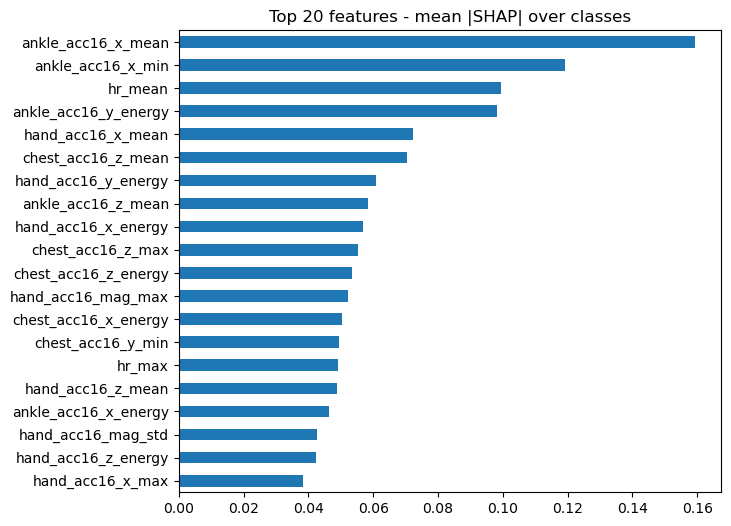

In [22]:
import pickle, tarfile
test = read_parquet("test.parquet").reset_index(drop=True)
sample = test.sample(n=min(200, len(test)), random_state=0)

# Model artifact of the evaluated package -> Booster
model_data = sm.describe_model_package(ModelPackageName=PKG_ARN)["InferenceSpecification"]["Containers"][0]["ModelDataUrl"]
with tarfile.open(fileobj=io.BytesIO(read_bytes(model_data)), mode="r:gz") as tf:
    raw = tf.extractfile(next(m for m in tf.getmembers() if m.isfile())).read()
booster = xgb.Booster()
try:
    booster.load_model(bytearray(raw))   # built-in algorithm's native format
except xgb.core.XGBoostError:
    booster = pickle.loads(raw)          # older containers pickle the Booster
print("Model:", model_data)

# Exact TreeSHAP; multiclass -> (n, K, F+1), last column is the bias term. NaNs use the model's missing-value paths.
contribs = booster.predict(xgb.DMatrix(sample[FEATURES].to_numpy(float)), pred_contribs=True)
assert contribs.shape == (len(sample), K, len(FEATURES) + 1), contribs.shape
mean_abs = np.abs(contribs[:, :, :-1]).mean(axis=0)               # (K, F)
class_names = [ACTIVITY_NAMES[LABEL_MAP[i]] for i in range(K)]
global_imp = pd.Series(mean_abs.mean(axis=0), index=FEATURES).sort_values(ascending=False)
per_class = pd.DataFrame(mean_abs.T, index=FEATURES, columns=class_names)

shap_dir = SHAP_OUT + time.strftime("%Y%m%d-%H%M%S") + "/"
write_json(shap_dir + "analysis.json", {
    "method": "xgboost exact TreeSHAP (pred_contribs)", "model_package_arn": PKG_ARN, "model_data": model_data,
    "n_samples": len(sample), "agg_method": "mean_abs",
    "global_shap_values": global_imp.to_dict(),
    "per_class_shap_values": {c: per_class[c].to_dict() for c in class_names}})
top = per_class.loc[global_imp.index[:20]].assign(overall=global_imp[:20])
put_text(shap_dir + "report.html", "<html><head><meta charset='utf-8'><title>SHAP report</title></head><body>"
         f"<h1>SHAP explainability (mean |SHAP|, {len(sample)} test windows)</h1>"
         f"<p>Exact TreeSHAP on {PKG_ARN}</p>" + top.round(4).to_html() + "</body></html>")
print("SHAP output:", shap_dir)
display(top.round(4))
global_imp[:20][::-1].plot.barh(figsize=(7, 6), title="Top 20 features - mean |SHAP| over classes");

### Consolidated report index

In [23]:
dq, mq = latest_subprefix(MON("data-quality/runs/")), latest_subprefix(MON("model-quality/runs/"))
shap_run = latest_subprefix(SHAP_OUT)
pipe_eval = read_json(REPORTS + "xgboost_eval.json")
pipe_run = latest_subprefix(MON("pipeline/runs/"))
cands = {
    "data_quality_baseline_statistics": MON("data-quality/baseline/statistics.json"),
    "data_quality_baseline_constraints": MON("data-quality/baseline/constraints.json"),
    "data_quality_violations": dq and dq + "constraint_violations.json",
    "data_quality_violations_summary": dq and dq + "violations_summary.json",
    "model_quality_baseline_statistics": MON("model-quality/baseline/statistics.json"),
    "model_quality_baseline_constraints": MON("model-quality/baseline/constraints.json"),
    "model_quality_violations": mq and mq + "constraint_violations.json",
    "model_quality_violations_summary": mq and mq + "violations_summary.json",
    "pipeline_evaluation": pipe_eval.get("evaluation_uri"),
    "pipeline_predictions": pipe_eval.get("predictions_uri"),
    "pipeline_status_summary": pipe_run and pipe_run + "summary.json",
    "shap_analysis": shap_run and shap_run + "analysis.json",
    "shap_report_html": shap_run and shap_run + "report.html",
}
# a violations file legitimately absent means zero violations; keep the summary as the evidence
cands = {k: (v if v and exists(v) else None) for k, v in cands.items()}
index = M.report_index(cands)
write_json(MON("reports/index.json"), index)
display(pd.DataFrame([{"report": k, "uri": v, "exists": exists(v)} for k, v in index["reports"].items()]))
print("Not found (job did not emit them or has not run):", index["missing"])

Wrote s3://pamap2-har-887757489409-us-east-1/monitoring/reports/index.json


,report,uri,exists
0,data_quality_baseline_statistics,s3://pamap2-har-887757489409-us-east-1/monitor...,True
1,data_quality_baseline_constraints,s3://pamap2-har-887757489409-us-east-1/monitor...,True
2,data_quality_violations,s3://pamap2-har-887757489409-us-east-1/monitor...,True
3,data_quality_violations_summary,s3://pamap2-har-887757489409-us-east-1/monitor...,True
4,model_quality_baseline_statistics,s3://pamap2-har-887757489409-us-east-1/monitor...,True
5,model_quality_baseline_constraints,s3://pamap2-har-887757489409-us-east-1/monitor...,True
6,model_quality_violations,s3://pamap2-har-887757489409-us-east-1/monitor...,True
7,model_quality_violations_summary,s3://pamap2-har-887757489409-us-east-1/monitor...,True
8,pipeline_evaluation,s3://pamap2-har-887757489409-us-east-1/models/...,True
9,pipeline_predictions,s3://pamap2-har-887757489409-us-east-1/models/...,True


Not found (job did not emit them or has not run): []


## Cleanup

Runs once for all sections above: nothing here creates schedules or endpoints; lists them, deletes only temporary pamap2-har-mon* models, warns about still-running jobs.

In [24]:
# Cleanup: nothing here creates schedules or endpoints; list them, delete only temporary pamap2-har-mon* models.
for page in sm.get_paginator("list_monitoring_schedules").paginate(NameContains=cfg["prefix"]):
    for x in page["MonitoringScheduleSummaries"]:
        print("WARNING: monitoring schedule exists (not deleted):", x["MonitoringScheduleName"])
for page in sm.get_paginator("list_models").paginate(NameContains=f"{cfg['prefix']}-mon"):
    for m in page["Models"]:
        if m["ModelName"].startswith(f"{cfg['prefix']}-mon"):
            print("Deleting temporary model", m["ModelName"])
            sm.delete_model(ModelName=m["ModelName"])
for kind, pager, key, field in (("processing", "list_processing_jobs", "ProcessingJobSummaries", "ProcessingJobName"),
                                ("transform", "list_transform_jobs", "TransformJobSummaries", "TransformJobName")):
    for page in sm.get_paginator(pager).paginate(StatusEquals="InProgress", NameContains=cfg["prefix"]):
        for x in page[key]:
            print("WARNING: still running", kind, "job:", x[field])
try:
    for e in sm.list_pipeline_executions(PipelineName=cfg["pipeline_name"])["PipelineExecutionSummaries"]:
        if e["PipelineExecutionStatus"] == "Executing":
            print("WARNING: still running pipeline execution:", e["PipelineExecutionArn"])
except ClientError as e:
    if e.response["Error"]["Code"] not in ("ResourceNotFound", "ValidationException"):
        raise
print("Endpoints:", [e["EndpointName"] for p in sm.get_paginator("list_endpoints").paginate() for e in p["Endpoints"]])

Endpoints: []
